# 20 · DSPy: from hand-written prompts to optimized programs

In notebook 06, `qwen2.5:3b` classified Banking77 messages into 77 intents with hand-written prompts: **48.9 %** zero-shot and **61.9 %** with one example per intent. Every prompt in this course so far was written and tuned by hand. That is slow, it does not transfer when the model changes, and nobody can say whether a better prompt exists.

**DSPy** (Stanford NLP, ~39k stars, listed in Good AI List under agent frameworks) treats the prompt as a *parameter* of a program:
- you declare **what** a step does (a *signature*: inputs and outputs with types);
- a *module* decides **how** to prompt for it (plain prediction, chain of thought, ReAct);
- an *optimizer* searches the instructions and few-shot examples that maximize **your metric** on **your data**.

| part | here | measured |
|---|---|---|
| signatures and modules | a typed classifier with a `Literal` of 77 intents | the prompt DSPy writes, accuracy zero-shot and with chain of thought |
| few-shot from data | random labeled examples; nearest-neighbour examples per message (`KNNFewShot`) | accuracy, prompt size, and whether the LLM beats plain retrieval |
| optimizers | `BootstrapFewShotWithRandomSearch`, `MIPROv2`, `GEPA` (a 7B model writes instructions for the 3B one) | accuracy, LM calls and minutes spent optimizing |
| combining | a bigger model with kNN demos; a router that answers with the neighbours' vote when they agree; GEPA on the kNN program | accuracy, latency and LLM calls per message |
| deployment | save and reload the optimized program | same predictions after reloading |

All runs use the same 231-message test sample as notebook 06 (3 per intent), so the numbers are directly comparable and paired.

Read it **after notebook 19** (prompt patterns). It also uses the structured output of notebook 16 and the embeddings of notebook 17.

**Sources.** Khattab et al. (2023), *DSPy: Compiling Declarative Language Model Calls into Self-Improving Pipelines*; Opsahl-Ong et al. (2024), *Optimizing Instructions and Demonstrations for Multi-Stage Language Model Programs* (MIPROv2); Agrawal et al. (2025), *GEPA: Reflective Prompt Evolution Can Outperform Reinforcement Learning*; Huyen, *AI Engineering*, ch. 5 (prompt engineering); Liu et al. (2021), *What Makes Good In-Context Examples for GPT-3?* (nearest-neighbour demonstrations).

## Background: prompts as programs

**Signature.** `message: str -> intent: Literal[...]` says what goes in and out, with an optional docstring as the task description. It says nothing about wording.

**Module.** `dspy.Predict(signature)` turns a signature into a prompt through an **adapter**. The default `ChatAdapter` writes the field names, types and allowed values into the system message and asks the model to answer in delimited fields (`[[ ## intent ## ]]`), which it then parses and type-checks. `dspy.ChainOfThought` adds a `reasoning` output before the answer. Modules compose like PyTorch layers, so a pipeline (retrieve → rerank → answer) is one program with several predictors.

**Demos.** Each predictor holds a list of demonstrations (input/output examples) that the adapter places in the prompt as earlier turns. Most optimizers work by choosing these demos, the instruction text, or both.

**Optimizers**, from cheapest to most expensive:

| optimizer | what it changes | how |
|---|---|---|
| `LabeledFewShot` | demos | k random labeled training examples |
| `KNNFewShot` | demos, **per input** | the k training examples nearest to the input in an embedding space |
| `BootstrapFewShot(WithRandomSearch)` | demos | runs the program on training data, keeps traces where the metric passes (useful when demos need intermediate steps such as reasoning); random search over several demo sets, scored on a validation set |
| `MIPROv2` | instruction **and** demos | a *prompt model* proposes candidate instructions from the data, the program and tips; Bayesian optimization (Optuna TPE) picks the instruction/demo combination, scored on minibatches |
| `GEPA` | instruction | runs the program, gives a *reflection model* the failures with textual feedback from the metric, and evolves instructions, keeping a Pareto front of candidates that win on different examples |

**The metric is the specification.** An optimizer maximizes exactly what the metric measures on exactly the data you give it. With a small validation set it overfits, and a better validation score is only a hypothesis until the held-out test confirms it.

In [1]:
import os; os.environ["TQDM_DISABLE"] = "1"   # before tqdm is imported: no progress bars from DSPy's evaluators and optimizers

import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-28-dspy")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : off (add LANGSMITH_API_KEY to .env to enable)


In [2]:
warnings.filterwarnings("ignore")
import logging, re
from typing import Literal
from collections import Counter, defaultdict
import datasets, dspy
from datasets import load_dataset
from huggingface_hub.utils import logging as hf_logging; hf_logging.set_verbosity_error()
from sentence_transformers import SentenceTransformer
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff
datasets.disable_progress_bars()
for name in ("dspy", "optuna", "LiteLLM", "httpx"):
    logging.getLogger(name).setLevel(logging.ERROR)
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

# Same data and the same 231-message test sample as notebook 06
ds = load_dataset("PolyAI/banking77")
LABELS = ds["train"].features["label"].names
split = ds["train"].train_test_split(test_size=0.1, seed=0, stratify_by_column="label")
train_ds, valid_ds, test_ds = split["train"], split["test"], ds["test"]
y_test = np.array(test_ds["label"])
rng = np.random.default_rng(0)
SUB = np.sort(np.concatenate([rng.choice(np.where(y_test == c)[0], 3, replace=False) for c in range(len(LABELS))]))
test = [dspy.Example(message=test_ds[int(i)]["text"], intent=LABELS[y_test[i]]).with_inputs("message") for i in SUB]

def examples(d, per_intent, seed):
    r = np.random.default_rng(seed); y = np.array(d["label"]); idx = []
    for c in range(len(LABELS)):
        idx += list(r.choice(np.where(y == c)[0], per_intent, replace=False))
    r.shuffle(idx)
    return [dspy.Example(message=d[int(i)]["text"], intent=LABELS[d[int(i)]["label"]]).with_inputs("message") for i in idx]
trainset = examples(train_ds, 2, seed=1)          # 154 labeled examples for the optimizers
valset = examples(valid_ds, 1, seed=2)            # 77, one per intent, for choosing between candidates
print(f"{len(LABELS)} intents | optimizer train {len(trainset)} | validation {len(valset)} | test {len(test)} (notebook 06's sample)")

W1110 15:24:05.217000 34640 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


77 intents | optimizer train 154 | validation 77 | test 231 (notebook 06's sample)


## 1. A signature, a module and the prompt DSPy writes

`dspy.LM` talks to Ollama directly, through its OpenAI-compatible endpoint and DSPy's own HTTP client (`engine="lm15"`; litellm is optional since DSPy 3.5). We turn its cache off so that every call is a real call and the timings are honest, and we count calls with a callback, the hook DSPy offers for logging and tracing.

In [3]:
class CallCounter(dspy.utils.callback.BaseCallback):
    def __init__(self): self.calls = Counter()
    def on_lm_start(self, call_id, instance, inputs): self.calls[instance.model] += 1
COUNTER = CallCounter()
BASE = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434")
# engine="lm15": DSPy's built-in client (no litellm), through Ollama's OpenAI-compatible endpoint
lm3 = dspy.LM("ollama_chat/qwen2.5:3b", base_url=BASE + "/v1", engine="lm15", temperature=0.0, max_tokens=400, cache=False)
lm7 = dspy.LM("ollama_chat/qwen2.5:7b", base_url=BASE + "/v1", engine="lm15", temperature=0.7, max_tokens=2000, cache=False)
dspy.configure(lm=lm3, callbacks=[COUNTER])

class Classify(dspy.Signature):
    """Classify a bank customer's message into exactly one intent."""
    message: str = dspy.InputField()
    intent: Literal[tuple(LABELS)] = dspy.OutputField()

zero = dspy.Predict(Classify)
print(zero(message="I still haven't received my new card, it's been two weeks."))
msgs = dspy.ChatAdapter().format(Classify, demos=[], inputs={"message": "I still haven't received my new card"})
# DSPy 3.5 returns a Prompt: a system text plus messages made of parts
chat = [("system", str(msgs.system))] + [(m.role, "".join(getattr(part, "text", "") for part in m.parts)) for m in msgs.messages]
for role, c in chat:
    print(f"--- {role} ({len(c)} characters)\n{c[:900]}{' [...]' if len(c) > 900 else ''}\n{c[-350:] if len(c) > 900 else ''}")

Prediction(
    intent='card_delivery_estimate'
)
--- system (4079 characters)
Your input fields are:
1. `message` (str):
Your output fields are:
1. `intent` (Literal['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire', 'card_acceptance', 'card_arrival', 'card_delivery_estimate', 'card_linking', 'card_not_working', 'card_payment_fee_charged', 'card_payment_not_recognised', 'card_payment_wrong_exchange_rate', 'card_swallowed', 'cash_withdrawal_charge', 'cash_withdrawal_not_recognised', 'change_pin', 'compromised_card', 'contactless_not_working', 'country_support', 'declined_card_payment', 'declined_cash_withdrawal', 'declined_transfer', 'direct_debit_payment_not_recognised', 'disposable_card_limits', 'edit_personal_details', 'exchange_charge', 'exchange_rate', 'e [...]
y_identity; ve

The adapter wrote the prompt for us: the task description from the docstring, the input and output fields, the 77 allowed values of the `Literal`, and the format to answer in. Changing the model or the adapter changes the prompt without touching the program.

## 2. A careful evaluation loop

`dspy.Evaluate` exists, but here we want more than the mean: per-example scores for paired comparisons, outputs that do not parse (counted as wrong), latency, and LM calls.

In [4]:
def metric(gold, pred, trace=None):
    return float(getattr(pred, "intent", None) == gold.intent)

RES = {}
def evaluate(name, program, data=test, store=True):
    scores, times, errors = [], [], 0
    calls0 = sum(COUNTER.calls.values())
    for ex in data:
        t0 = time.time()
        try:
            pred = program(message=ex.message); s = metric(ex, pred)
        except Exception:                          # an output the adapter cannot parse into one of the 77 intents
            s, errors = 0.0, errors + 1
        scores.append(s); times.append(time.time() - t0)
    acc, lo, hi = bootstrap_ci(scores)
    r = dict(scores=np.array(scores), acc=acc, ci=(lo, hi), errors=errors, latency=float(np.median(times)),
             calls_per_msg=(sum(COUNTER.calls.values()) - calls0) / len(data))
    if store: RES[name] = r
    print(f"{name:42s} accuracy {acc:.3f} [{lo:.3f}, {hi:.3f}] | unparsable {errors:3d} | median {r['latency']:.2f}s per message")
    return r

evaluate("Predict, zero-shot", zero)
evaluate("ChainOfThought, zero-shot", dspy.ChainOfThought(Classify));

Predict, zero-shot                         accuracy 0.558 [0.489, 0.623] | unparsable   0 | median 0.36s per message


ChainOfThought, zero-shot                  accuracy 0.541 [0.472, 0.602] | unparsable   2 | median 0.83s per message


**What zero-shot DSPy gives.**
- **The prompt DSPy writes beats the hand-written one.** `Predict` reaches **0.558** [0.489, 0.623] against notebook 06's hand-written zero-shot prompt with JSON-schema output (0.489), with the same model and messages.

  The adapter's prompt is long: about 4,100 characters of system message and 2,100 of user message. It lists the 77 allowed values twice and fixes a strict output format. 0 of 231 answers were unparsable.
- **Chain of thought does not help here** (0.541, and 2 unparsable answers). It doubles the latency (0.83 s vs 0.36 s per message).

  Reasoning helps when the answer has to be *derived*. Here it has to be *recalled*: which of 77 similar-sounding labels the bank uses for this message. A 3B model reasoning about "card_arrival" vs "card_delivery_estimate" just adds tokens.
- About 45% of the messages are wrong with 77 labels and no examples. The question for the rest of the notebook is what information the model is missing.

## 3. Few-shot from data: random examples vs nearest neighbours

Two ways to choose demos without any optimization loop:
- **`LabeledFewShot(k=16)`**: 16 random labeled examples, the same for every message.
- **Nearest neighbours** (what `dspy.KNNFewShot` does): embed all ~9,000 training messages once, and for each new message put its k most similar training messages, with their intents, in the prompt. The model then sees examples of exactly the intents it is likely confusing. We write it as a 10-line module to show how little is behind it, and as a baseline we also score **retrieval alone**: the majority intent of the 8 neighbours, with no LLM at all.

In [5]:
evaluate("LabeledFewShot, 16 random demos", dspy.LabeledFewShot(k=16).compile(dspy.Predict(Classify), trainset=trainset))

encoder = SentenceTransformer("BAAI/bge-small-en-v1.5", device=device)
pool = [dspy.Example(message=t, intent=LABELS[l]).with_inputs("message") for t, l in zip(train_ds["text"], train_ds["label"])]
t0 = time.time(); POOL_EMB = encoder.encode([e.message for e in pool], normalize_embeddings=True, batch_size=256)
print(f"embedded {len(pool):,} training messages in {time.time() - t0:.0f}s")
def neighbours(message, k):
    q = encoder.encode([message], normalize_embeddings=True)[0]
    return np.argsort(-POOL_EMB @ q)[:k]

class KNNClassify(dspy.Module):
    """Per-message demos: the k nearest training examples (what dspy.KNNFewShot does)."""
    def __init__(self, k):
        super().__init__(); self.k, self.predict = k, dspy.Predict(Classify)
    def forward(self, message):
        self.predict.demos = [pool[i] for i in neighbours(message, self.k)[::-1]]   # the most similar one last, closest to the question
        return self.predict(message=message)

class KNNVote(dspy.Module):
    """No LLM: the majority intent of the k nearest training examples."""
    def __init__(self, k): super().__init__(); self.k = k
    def forward(self, message):
        return dspy.Prediction(intent=Counter(pool[i].intent for i in neighbours(message, self.k)).most_common(1)[0][0])

evaluate("retrieval only: 8-NN vote (no LLM)", KNNVote(8))
for k in (4, 8, 16):
    evaluate(f"kNN demos, k={k}", KNNClassify(k))

LabeledFewShot, 16 random demos            accuracy 0.433 [0.368, 0.498] | unparsable   0 | median 0.39s per message


embedded 9,002 training messages in 4s


retrieval only: 8-NN vote (no LLM)         accuracy 0.913 [0.874, 0.948] | unparsable   0 | median 0.02s per message


kNN demos, k=4                             accuracy 0.818 [0.766, 0.866] | unparsable   0 | median 0.46s per message


kNN demos, k=8                             accuracy 0.848 [0.801, 0.896] | unparsable   0 | median 0.52s per message


kNN demos, k=16                            accuracy 0.870 [0.827, 0.909] | unparsable   1 | median 0.68s per message


**What the demos show.**
- **Random examples hurt:** 16 random demos drop accuracy to **0.433** (−0.126 vs zero-shot). With 77 classes, 16 random examples cover at most 16 intents, and they pull the model towards those labels.
- **Relevant examples help a lot:** with the k nearest training messages as demos, accuracy rises with k: **0.818** (k = 4), **0.848** (k = 8) and **0.870** (k = 16). The model now sees how the bank labels messages that look like this one.
- **Retrieval alone wins.** The majority intent of the 8 nearest neighbours, with no LLM at all, reaches **0.913** in 0.02 s per message, 18 to 34 times faster than the LLM variants.

  With 9,000 labeled examples and a good embedding model, this task is mostly *lookup*. The LLM with kNN demos is slightly *worse* than the vote it was given, because it sometimes overrides a clear majority. This is the honest baseline every LLM classifier should be compared against (notebook 17).

## 4. Optimizers: searching demos and instructions

Now the optimizers that *search*, all starting from the zero-shot `Predict` and scored on the 77-message validation set:
- **`BootstrapFewShotWithRandomSearch`**: 6 candidate demo sets (up to 4 bootstrapped + 8 labeled demos each), keep the best on validation.
- **`MIPROv2`, `auto="light"`**: `qwen2.5:7b` proposes 6 instructions after reading a summary of the data and the program; Bayesian search over instruction × demo set, on minibatches.
- **`GEPA`**: `qwen2.5:7b` reads the 3B model's mistakes with feedback ("predicted X, the correct intent was Y") and rewrites the instruction, budget of 600 metric calls. GEPA optimizes the instruction only, so it starts from zero-shot.

We record the LM calls and minutes each one costs, which is the price of the optimization, paid once.

In [6]:
import contextlib, io
OPT = {}
def optimize(name, fn):
    c0 = Counter(COUNTER.calls); t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # silence DSPy's progress bars and logs
        program = fn()
    calls = {m.split("/")[-1]: COUNTER.calls[m] - c0[m] for m in COUNTER.calls if COUNTER.calls[m] - c0[m]}
    OPT[name] = dict(minutes=(time.time() - t0) / 60, calls=calls, program=program)
    print(f"{name}: optimized in {OPT[name]['minutes']:.1f} min with {calls} LM calls")
    return program

rs = optimize("BootstrapFewShotWithRandomSearch", lambda: dspy.BootstrapFewShotWithRandomSearch(
    metric=metric, max_bootstrapped_demos=4, max_labeled_demos=8, num_candidate_programs=6, num_threads=1)
    .compile(dspy.Predict(Classify), trainset=trainset, valset=valset))
evaluate("BootstrapFewShotWithRandomSearch", rs);

BootstrapFewShotWithRandomSearch: optimized in 4.7 min with {'qwen2.5:3b': 750} LM calls
BootstrapFewShotWithRandomSearch           accuracy 0.558 [0.489, 0.623] | unparsable   0 | median 0.37s per message


In [7]:
mipro = optimize("MIPROv2 (light)", lambda: dspy.MIPROv2(
    metric=metric, prompt_model=lm7, task_model=lm3, auto="light", max_bootstrapped_demos=4, max_labeled_demos=4,
    num_threads=1, seed=0, verbose=False)
    .compile(dspy.Predict(Classify), trainset=trainset, valset=valset, minibatch_size=25))
print("instruction found:", mipro.signature.instructions)
print("demos:", len(mipro.demos))
evaluate("MIPROv2 (light)", mipro);

MIPROv2 (light): optimized in 6.8 min with {'qwen2.5:3b': 645, 'qwen2.5:7b': 20} LM calls
instruction found: Classify a bank customer's message into exactly one intent.
demos: 0
MIPROv2 (light)                            accuracy 0.554 [0.485, 0.619] | unparsable   0 | median 0.37s per message


In [8]:
def feedback_metric(gold, pred, trace=None, pred_name=None, pred_trace=None):
    got = getattr(pred, "intent", None)
    ok = got == gold.intent
    return dspy.Prediction(score=float(ok), feedback="Correct." if ok else
                           f"Wrong: predicted '{got}', but the correct intent for this message is '{gold.intent}'.")

gepa = optimize("GEPA", lambda: dspy.GEPA(
    metric=feedback_metric, reflection_lm=lm7, max_metric_calls=600, reflection_minibatch_size=5, num_threads=1, seed=0)
    .compile(dspy.Predict(Classify), trainset=trainset, valset=valset))
print("instruction found:\n", gepa.signature.instructions[:1500])
evaluate("GEPA", gepa);

GEPA: optimized in 8.5 min with {'qwen2.5:3b': 861, 'qwen2.5:7b': 7} LM calls
instruction found:
 Classify a bank customer's message into exactly one intent based on the primary action or inquiry the customer is making. Each message should be categorized into one of the following intents: 'exchange_via_app', 'exchange_charge', 'fiat_currency_support', 'topping_up_by_card', 'transfer_into_account', 'top_up_by_bank_transfer_charge', 'declined_transfer', 'visa_or_mastercard', 'card_payment_wrong_exchange_rate', 'card_payment_fee_charged', and 'terminate_account'. Please refer to the following examples and feedback to understand the correct intent classification for different types of customer messages:

1. Message: 'How can I exchange USD and GBP in the app?' 
   - Correct intent: 'exchange_via_app' 
   - Feedback: 'Wrong: predicted "exchange_rate", but the correct intent for this message is "exchange_via_app".'

2. Message: 'What information am I going to have to have in order to do a tr

**What the optimizers found.**
- **Nothing better than the starting point**, on the test sample:
  - BootstrapFewShotWithRandomSearch: 0.558;
  - MIPROv2: 0.554;
  - GEPA: 0.554.

  All three are within ±0.004 of zero-shot `Predict`, which is noise: two runs of this notebook differed by that much.
- **Each optimizer, in detail:**
  - **BootstrapFewShotWithRandomSearch** scored 9 candidates on the 77 validation messages. The best (53.25%) was the *unoptimized* program, so it returned it. The other candidates (labeled and bootstrapped demo sets) reached at most 50.65%: 4 demos out of 77 intents are mostly irrelevant to the next message, the same lesson as `LabeledFewShot`.
  - **MIPROv2** (20 calls to the 7B to propose instructions, 645 calls to the 3B to evaluate them) also kept the original instruction and no demos.
  - **GEPA** rewrote the instruction into a long text with five worked examples and the reflection model's feedback. It scored 59.7% on validation and 0.554 on the test: the instruction overfits the handful of validation failures it was written from.
- **Cost:** 5 to 9 minutes and 650 to 870 LM calls each, paid once.
- **The lesson.** An optimizer searches *within* the space you give it, here instructions and a few static demos. When the missing ingredient is *per-message information* (which labeled messages look like this one), no instruction can supply it. Optimizers shine on multi-step programs with a stable task description, not on 77-way lookup tasks.

## 5. Combining what works

The optimizers searched around a weak starting point: zero-shot `Predict`, where the model has to recall 77 intent names from a list. Section 3 showed what actually helps on this task, retrieving similar labeled messages. Three ways to build on it:
- **A bigger model with the same demos:** `qwen2.5:7b` (temperature 0) with the 16 nearest neighbours.
- **A router:** when the 8 nearest neighbours mostly agree, answer with their vote (no LLM call). Only the ambiguous messages go to the LLM with kNN demos. The agreement threshold is chosen on the validation set, never on the test. This is the cascade pattern of production classifiers: cheap and confident first, expensive only when needed.
- **GEPA on top of kNN demos:** optimize the *instruction* of the kNN program instead of the zero-shot one. During optimization a training message must not retrieve itself as a demo, otherwise the score would be inflated, so that neighbour is skipped.

In [9]:
lm7c = lm7.copy(temperature=0.0, max_tokens=400)          # the 7B as a classifier: greedy, short answers
with dspy.context(lm=lm7c):
    evaluate("kNN demos, k=16, qwen2.5:7b", KNNClassify(16))

class Router(dspy.Module):
    """Cascade: the 8-NN vote when at least `tau` of the 8 neighbours agree, otherwise the LLM with 16 kNN demos."""
    def __init__(self, tau):
        super().__init__(); self.tau, self.llm, self.routed = tau, KNNClassify(16), Counter()
    def forward(self, message):
        intent, votes = Counter(pool[i].intent for i in neighbours(message, 8)).most_common(1)[0]
        if votes >= self.tau:
            self.routed["vote"] += 1
            return dspy.Prediction(intent=intent)
        self.routed["llm"] += 1
        return self.llm(message=message)

print("threshold chosen on the validation set (77 messages, not the test):")
best_tau, best_acc = None, -1
for tau in range(3, 9):
    r = evaluate(f"  router tau={tau} (validation)", Router(tau), data=valset, store=False)
    if r["acc"] > best_acc: best_tau, best_acc = tau, r["acc"]
router = Router(best_tau)
evaluate(f"router: vote if >= {best_tau}/8 agree, else kNN LLM", router)
print(f"on the test sample, {router.routed['vote'] / sum(router.routed.values()):.0%} of the messages were answered by the vote alone")

kNN demos, k=16, qwen2.5:7b                accuracy 0.926 [0.892, 0.957] | unparsable   0 | median 1.62s per message
threshold chosen on the validation set (77 messages, not the test):


  router tau=3 (validation)                accuracy 0.935 [0.870, 0.987] | unparsable   0 | median 0.04s per message


  router tau=4 (validation)                accuracy 0.948 [0.896, 0.987] | unparsable   0 | median 0.03s per message


  router tau=5 (validation)                accuracy 0.948 [0.896, 0.987] | unparsable   0 | median 0.03s per message


  router tau=6 (validation)                accuracy 0.935 [0.883, 0.987] | unparsable   0 | median 0.03s per message


  router tau=7 (validation)                accuracy 0.922 [0.857, 0.974] | unparsable   0 | median 0.03s per message


  router tau=8 (validation)                accuracy 0.909 [0.844, 0.961] | unparsable   0 | median 0.03s per message


router: vote if >= 4/8 agree, else kNN LLM accuracy 0.922 [0.883, 0.957] | unparsable   0 | median 0.03s per message
on the test sample, 97% of the messages were answered by the vote alone


In [10]:
class KNNClassifyLOO(KNNClassify):
    """KNNClassify for optimization on training messages: skip a neighbour identical to the message itself."""
    def forward(self, message):
        idx = [i for i in neighbours(message, self.k + 1) if pool[i].message != message][:self.k]
        self.predict.demos = [pool[i] for i in idx[::-1]]
        return self.predict(message=message)

gepa_knn = optimize("GEPA on kNN demos", lambda: dspy.GEPA(
    metric=feedback_metric, reflection_lm=lm7, max_metric_calls=400, reflection_minibatch_size=5, num_threads=1, seed=0)
    .compile(KNNClassifyLOO(16), trainset=trainset, valset=valset))
print("instruction found:\n", gepa_knn.predict.signature.instructions[:1200])
final_knn = KNNClassify(16); final_knn.predict.signature = gepa_knn.predict.signature       # same instruction, normal retrieval
OPT["GEPA on kNN demos"]["program"] = final_knn
evaluate("GEPA on kNN demos", final_knn);

GEPA on kNN demos: optimized in 7.3 min with {'qwen2.5:3b': 406, 'qwen2.5:7b': 8} LM calls
instruction found:
 Classify a bank customer's message into exactly one intent.
GEPA on kNN demos                          accuracy 0.870 [0.827, 0.909] | unparsable   1 | median 0.69s per message


**What combining gives.**
- **The 7B with kNN demos reaches 0.926** [0.892, 0.957], the best accuracy in the notebook, and the first variant above retrieval alone (0.913). It costs 1.62 s per message, the slowest option.
- **The router reaches 0.922 in 0.03 s per message.**
  - The threshold was picked on validation: 4 of 8 neighbours agreeing (0.948 on validation).
  - On the test sample, **97% of the messages were answered by the vote alone**. The LLM saw only the 3% where the neighbours disagreed.
  - It is about as accurate as the 7B, at about 1/50 of the latency and 3% of the LLM calls. **This is the configuration to deploy.**
- **GEPA on top of kNN demos** kept the original instruction (0.870, the same as kNN demos without optimization), after 414 calls and 7 minutes. Once the right examples are in the prompt, the instruction no longer matters much.
- **Ranking, from worst to best:**
  - hand-written zero-shot: 0.489;
  - DSPy zero-shot: 0.558;
  - optimizers: ~0.55;
  - kNN demos: 0.870;
  - retrieval: 0.913;
  - router: 0.922;
  - 7B with kNN demos: 0.926.

  The large gains came from *what information reaches the model*, not from how the instruction is worded.

## 6. All results, paired

Every variant answered the same 231 messages, so we compare each with zero-shot `Predict` on the same examples (paired bootstrap), and put notebook 06's hand-written prompts next to them.

variant                                    accuracy      vs zero-shot Predict calls/msg  s/msg           optimization
Predict, zero-shot                            0.558  +0.000 [+0.000, +0.000]       1.1   0.36                       
ChainOfThought, zero-shot                     0.541  -0.017 [-0.061, +0.026]       1.0   0.83                       
LabeledFewShot, 16 random demos               0.433  -0.126 [-0.182, -0.074]       1.0   0.39                       
retrieval only: 8-NN vote (no LLM)            0.913  +0.355 [+0.290, +0.424]       0.0   0.02                       
kNN demos, k=4                                0.818  +0.260 [+0.199, +0.320]       1.0   0.46                       
kNN demos, k=8                                0.848  +0.290 [+0.216, +0.364]       1.0   0.52                       
kNN demos, k=16                               0.870  +0.312 [+0.247, +0.377]       1.0   0.68                       
BootstrapFewShotWithRandomSearch              0.558  +0.000 [+0

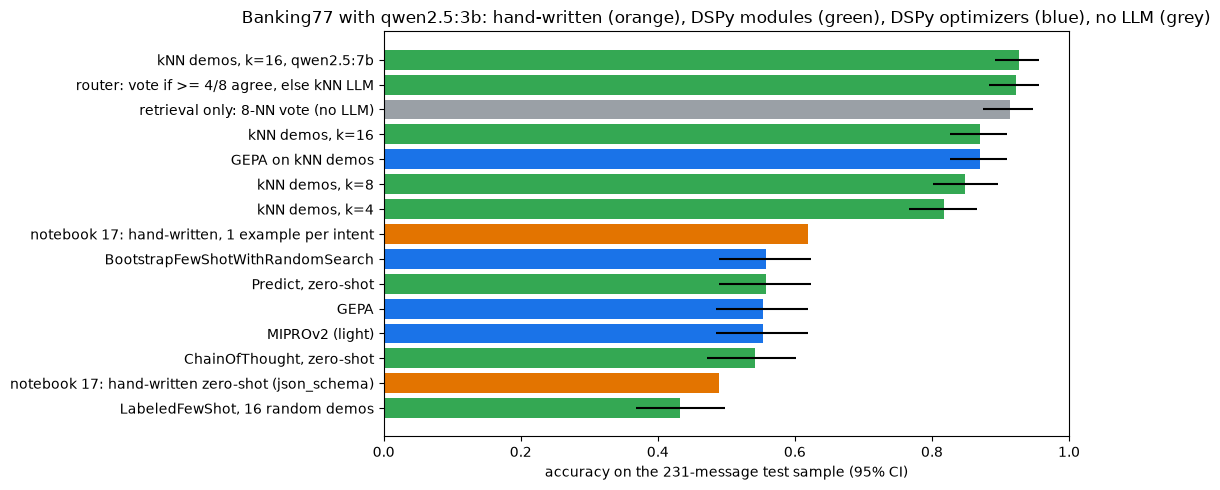

In [11]:
NB06 = {"notebook 06: hand-written zero-shot (json_schema)": 0.489, "notebook 06: hand-written, 1 example per intent": 0.619}
base = RES["Predict, zero-shot"]["scores"]
print(f"{'variant':42s} {'accuracy':>8s}  {'vs zero-shot Predict':>24s} {'calls/msg':>9s} {'s/msg':>6s} {'optimization':>22s}")
for name, r in RES.items():
    d, lo, hi = paired_bootstrap_diff(base, r["scores"])
    opt = f"{OPT[name]['minutes']:.0f} min, {sum(OPT[name]['calls'].values())} calls" if name in OPT else ""
    print(f"{name:42s} {r['acc']:8.3f}  {d:+.3f} [{lo:+.3f}, {hi:+.3f}] {r['calls_per_msg']:9.1f} {r['latency']:6.2f} {opt:>22s}")
for k, v in NB06.items():
    print(f"{k:42s} {v:8.3f}")

fig, ax = plt.subplots(figsize=(11, 5))
names = list(RES) + list(NB06)
accs = [RES[n]["acc"] for n in RES] + list(NB06.values())
errs = np.array([[RES[n]["acc"] - RES[n]["ci"][0], RES[n]["ci"][1] - RES[n]["acc"]] for n in RES] + [[0, 0]] * len(NB06)).T
colors = ["#9aa0a6" if "no LLM" in n else "#1a73e8" if n in OPT else "#e37400" if n.startswith("notebook") else "#34a853" for n in names]
order = np.argsort(accs)
ax.barh([names[i] for i in order], [accs[i] for i in order], xerr=errs[:, order], color=[colors[i] for i in order])
ax.set_xlabel("accuracy on the 231-message test sample (95% CI)"); ax.set_xlim(0, 1)
ax.set_title("Banking77 with qwen2.5:3b: hand-written (orange), DSPy modules (green), DSPy optimizers (blue), no LLM (grey)")
plt.tight_layout(); plt.show()

**Reading the paired table.**
- Every gain against zero-shot `Predict` that does not cross 0 is real on this sample:
  - kNN demos: +0.26 to +0.31;
  - retrieval: +0.355;
  - router: +0.364;
  - 7B kNN: +0.368.
- **No difference is shown** for:
  - the three optimizers on zero-shot;
  - chain of thought.
- **Random demos are significantly worse.**
- **Notebook 06's hand-written prompts sit at the bottom.** The one with 77 examples (one per intent, 0.619) is beaten by any variant that chooses its examples per message.

## 7. Shipping an optimized program

The output of an optimizer is data: instructions and demos. `save` writes them to JSON, which goes into version control and code review like any other artifact. In production you load it into the same program class, and you re-run the optimizer (not edit the JSON by hand) when the model, the data or the metric changes.

In [12]:
best_opt = max(OPT, key=lambda n: RES[n]["acc"])
path = os.path.join(ROOT, "data", "cache", "dspy_banking77_program.json")
OPT[best_opt]["program"].save(path)
saved = json.load(open(path, encoding="utf-8"))
print(f"best optimizer: {best_opt} | saved {os.path.getsize(path) / 1024:.1f} KB | keys: {list(saved)}")
best = OPT[best_opt]["program"]
reloaded = KNNClassify(best.k) if isinstance(best, KNNClassify) else dspy.Predict(Classify)   # same program class, then load
reloaded.load(path)
same = sum(reloaded(message=ex.message).intent == OPT[best_opt]["program"](message=ex.message).intent for ex in test[:30])
print(f"same prediction after reloading on {same}/30 messages")
os.remove(path)

best optimizer: GEPA on kNN demos | saved 2.4 KB | keys: ['predict', 'metadata']


same prediction after reloading on 30/30 messages


## Results

| question | measured (qwen2.5:3b unless noted, 231 test messages) | lesson |
|---|---|---|
| does a declared signature beat a hand-written prompt? | DSPy zero-shot 0.558 vs notebook 06's 0.489; 0 unparsable | typed signatures and adapters give a strong, model-agnostic default |
| chain of thought on a 77-way classification | 0.541, 2.3x slower | reasoning does not help with recall-type tasks |
| random vs relevant examples | 16 random demos 0.433; 16 nearest-neighbour demos 0.870 | the right examples matter more than the number |
| retrieval without an LLM | 8-NN vote 0.913 at 0.02 s per message | always compare against a non-LLM baseline |
| prompt optimizers | Bootstrap+RS 0.558, MIPROv2 0.554, GEPA 0.554 (5–9 min, 650–870 calls each) | no gain when the missing ingredient is per-message information; GEPA overfit the validation set |
| combining | router (vote if 4 of 8 agree, else LLM) 0.922 at 0.03 s, 97% answered without the LLM; 7B with kNN demos 0.926 at 1.6 s | cascade the cheap, confident path first |
| deployment | the optimized program saved as 2.4 KB of JSON; 30/30 identical predictions after reloading | an optimized prompt is a versioned artifact |

## In production

**Use DSPy-style programs when:**
- the pipeline has several LM steps;
- the model may change;
- you have a metric and a few hundred labeled examples.

Signatures make each step's contract explicit, and re-optimizing is cheaper than re-writing prompts by hand for a new model.

**Before optimizing prompts, fix the information flow.**
- Retrieve relevant examples or documents per request (kNN few-shot, RAG).
- Measure a non-LLM baseline (embeddings + kNN or logistic regression; notebook 17).
- Cascade: let a cheap, confident component answer and escalate the rest. The router here sent 3% of the traffic to the LLM with no loss of accuracy.

**When you do optimize:**
- Hold out a test set the optimizer never sees. GEPA improved validation from 0.55 to 0.60 and gained nothing on the test.
- Use a validation set large enough for the differences you care about: 77 examples cannot separate 0.55 from 0.56.
- Store the optimized program (JSON) in version control.
- Re-run the optimizer when the model, the data or the metric changes.

**Costs.** Optimization is paid once (here 400–900 calls), inference forever. Compare variants on accuracy, latency and calls per message together, as in the paired table.

**Failure modes.**
- Optimizing on a validation set too small, or overlapping with the training examples. Here the kNN demos had to exclude the message itself.
- Comparing against a weak baseline.
- Chain of thought by default.
- Trusting a reflective optimizer's long instruction: it tends to memorize the failures it saw.
- Silent output-format changes when switching models (check the unparsable count).

**Next:** notebook 21 (clustering and topic modeling), or notebook 29 to evaluate and trace LLM programs with Inspect and Phoenix.